# 18 — The Ty Jerome effect: have there been Ty Jeromes before, and how did they fare?

**Question.** Ty Jerome has led our live Most Improved race every day since his first game (about a 26% chance on 8 November). Should we believe a hot start like his? We look for every past player who looked like him **at the same point of the season**, and follow what happened next.

**Jerome on 8 November** (day 19 after opening night):
- **This season:** 26.6 points in 30.5 minutes over 8 games, with 2 missed.
- **His baseline season, 2024-25:** 12.5 points in 19.9 minutes, off the bench.
- **Age:** 29.6.

**Three groups of past players, all at day 19, 2000-01 → 2025-26** (players with 5+ games):
1. **Strict Ty Jeromes:** aged 27+, up 8+ points a game, and a bench role in the baseline season (24 minutes or fewer).
2. **The same, but under 27,** for contrast.
3. **The 12 nearest to Jerome** on age, baseline points and minutes, and points and minutes now.

**What we follow:** the jump at season's end (and the share of the early jump kept), games played, MIP votes, and what our model said at day 19. The model's chance is from a model that never saw that season (leave-one-season-out), with the same inputs as the live race.

Votes are used only to describe outcomes.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from unicorn import mip_history as MH
from unicorn.allstars import add_prior_allstar, load_selections
from unicorn.gamelogs import GAMELOG_SEASONS, build_game_table, load_game_logs
from unicorn.mip import ChoiceModel
from unicorn.plotting import BLUE, FIG_DIR, INK, INK2, MUTED, ORANGE, SURFACE, apply_style

warnings.filterwarnings("ignore")
apply_style()
DAY = 19                                     # 8 November 2026 = day 19 after opening night
g = MH.load_games(); info = MH.player_info(); votes, winners = MH.voting(g)
e = add_prior_allstar(MH.in_season_frame(g, info, winners, day=DAY), load_selections())
e = e[e["games"] >= 5].copy()

ss = g.groupby(["player_id", "season_start"]).agg(gp=("game_id", "size"), ppg=("pts", "mean"))
season_len = g.drop_duplicates(["team_id", "game_id"]).groupby("season_start").apply(lambda d: d.groupby("team_id")["game_id"].nunique().max())
key = list(zip(e["player_id"], e["season_start"]))
e["final_ppg"] = [ss["ppg"].get(k, np.nan) for k in key]
e["games_played"] = [ss["gp"].get(k, np.nan) for k in key]
e["share_of_games"] = e["games_played"] / e["season_start"].map(season_len)
e["early_jump"] = e["ppg"] - e["base_ppg"]
e["final_jump"] = e["final_ppg"] - e["base_ppg"]
e["kept"] = e["final_jump"] / e["early_jump"]
e["next_season_ppg"] = [ss["ppg"].get((p, y + 1), np.nan) for p, y in key]
vr = votes.dropna(subset=["player_id"]).assign(player_id=lambda v: v["player_id"].astype(int)).set_index(["season", "player_id"])["vote_rank"]
e["vote_rank"] = [vr.get((s, int(p)), np.nan) for s, p in zip(e["season"], e["player_id"])]

FEATS = MH.IN_SEASON_FEATURES + ["over_turn", "prior_allstar"]       # the live race's inputs (turning point 20)
d = MH.with_turn(e, "base_ppg", 20)
for s in d["season"].unique():
    te = d["season"] == s
    p = ChoiceModel(FEATS, MH.L2).fit(d[~te]).predict_proba(d[te])
    e.loc[te, "model chance"], e.loc[te, "model rank"] = p, p.rank(ascending=False, method="min")
print(f"{len(e):,} player-seasons at day {DAY}, 2000-01 → 2025-26")

7,057 player-seasons at day 19, 2000-01 → 2025-26


In [2]:
# Jerome himself, from the live season's game logs
live, _, _ = build_game_table(load_game_logs(GAMELOG_SEASONS + ["2026-27"]))
live["day"] = (live["game_date"] - live.groupby("season")["game_date"].transform("min")).dt.days
tj = live[live["player_name"] == "Ty Jerome"]
career = tj.groupby("season").agg(games=("game_id", "size"), points=("pts", "mean"), minutes=("min", "mean")).round(1)
now = tj[(tj["season"] == "2026-27") & (tj["day"] <= DAY)]
print(f"2026-27 to day {DAY}: {len(now)} games, {now['pts'].mean():.1f} points; without his 45-point opener: {now['pts'].iloc[1:].mean():.1f}")
career

2026-27 to day 19: 8 games, 26.6 points; without his 45-point opener: 24.0


,games,points,minutes
season,,,
2019-20,31,3.3,10.5
2020-21,33,10.7,23.9
2021-22,48,7.1,16.7
2022-23,45,6.9,18.2
2023-24,2,2.0,7.5
2024-25,70,12.5,19.9
2025-26,15,19.7,22.7
2026-27,8,26.6,30.5


## 18A — Past Ty Jeromes

In [3]:
SHOW = ["season", "player_name", "age", "games", "base_ppg", "base_mpg", "ppg", "mpg", "model rank", "model chance", "final_ppg", "kept", "share_of_games", "vote_rank", "next_season_ppg"]
FMT = {"age": "{:.0f}", "base_ppg": "{:.1f}", "base_mpg": "{:.1f}", "ppg": "{:.1f}", "mpg": "{:.1f}", "model rank": "{:.0f}", "model chance": "{:.1%}",
       "final_ppg": "{:.1f}", "kept": "{:.0%}", "share_of_games": "{:.0%}", "vote_rank": "{:.0f}", "next_season_ppg": "{:.1f}"}

def summary(x):
    return {"players": len(x), "early jump (median)": x["early_jump"].median(), "season-end jump (median)": x["final_jump"].median(),
            "share of jump kept (median)": x["kept"].median(), "played 70%+ of games": (x["share_of_games"] >= 0.7).mean(),
            "got votes": int(x["vote_rank"].notna().sum()), "top 3": int((x["vote_rank"] <= 3).sum()), "won": int(x["mip"].sum()),
            "model's expected wins": x["model chance"].sum(), "model's highest chance": x["model chance"].max()}

hot = (e["early_jump"] >= 8)
strict = e[hot & (e["age"] >= 27) & (e["base_mpg"] <= 24)]
young = e[hot & (e["age"] < 27) & (e["base_mpg"] <= 24)]
JEROME = {"age": 29.6, "base_ppg": 12.5, "base_mpg": 19.9, "ppg": 26.6, "mpg": 30.5}
sd = {k: e[k].std() for k in JEROME}
e["distance to Jerome"] = np.sqrt(sum(((e[k] - v) / sd[k]) ** 2 for k, v in JEROME.items()))
nearest = e.nsmallest(12, "distance to Jerome")
groups = pd.DataFrame({"strict Ty Jeromes (27+)": summary(strict), "same, under 27": summary(young),
                       "everyone 27+ up 8+ points (any role)": summary(e[hot & (e["age"] >= 27)]),
                       "12 nearest to Jerome": summary(nearest), "everyone up 8+ points": summary(e[hot])}).T
display(groups.style.format({"early jump (median)": "{:+.1f}", "season-end jump (median)": "{:+.1f}", "share of jump kept (median)": "{:.0%}",
                     "played 70%+ of games": "{:.0%}", "model's expected wins": "{:.1f}", "model's highest chance": "{:.0%}"}))
print("winners among everyone up 8+ points at day 19:")
display(e[hot & e["mip"]][["season", "player_name", "age", "base_mpg", "base_ppg", "ppg"]].round(1).style.hide(axis="index"))

,players,early jump (median),season-end jump (median),share of jump kept (median),played 70%+ of games,got votes,top 3,won,model's expected wins,model's highest chance
strict Ty Jeromes (27+),14.000000,+9.5,+6.2,65%,64%,3.000000,0.000000,0.000000,0.4,9%
"same, under 27",53.000000,+9.2,+7.9,79%,79%,25.000000,6.000000,3.000000,3.7,38%
everyone 27+ up 8+ points (any role),31.000000,+9.4,+5.1,58%,74%,7.000000,1.000000,1.000000,1.2,37%
12 nearest to Jerome,12.000000,+7.1,+5.5,61%,67%,5.000000,1.000000,0.000000,0.6,20%
everyone up 8+ points,112.000000,+9.1,+6.9,73%,80%,51.000000,16.000000,7.000000,8.0,41%


winners among everyone up 8+ points at day 19:


season,player_name,age,base_mpg,base_ppg,ppg
2003-04,Zach Randolph,22.000000,16.900000,8.400000,20.100000
2004-05,Bobby Simmons,25.000000,24.600000,7.800000,16.000000
2006-07,Monta Ellis,21.000000,18.000000,6.800000,17.500000
2014-15,Jimmy Butler III,25.400000,38.700000,13.100000,21.200000
2015-16,CJ McCollum,24.400000,15.700000,6.800000,20.900000
2025-26,Nickeil Alexander-Walker,27.400000,25.300000,9.400000,17.600000
2023-24,Tyrese Maxey,23.200000,33.600000,20.300000,28.600000


In [4]:
print("STRICT TY JEROMES: aged 27+, up 8+ points at day 19, 24 minutes or fewer in the baseline season")
strict.sort_values("early_jump", ascending=False)[SHOW].style.format(FMT, na_rep="–").hide(axis="index")

STRICT TY JEROMES: aged 27+, up 8+ points at day 19, 24 minutes or fewer in the baseline season


season,player_name,age,games,base_ppg,base_mpg,ppg,mpg,model rank,model chance,final_ppg,kept,share_of_games,vote_rank,next_season_ppg
2014-15,AJ Price,28,6,1.6,3.5,13.0,20.5,7,2.8%,5.1,31%,32%,–,–
2000-01,Brian Grant,29,10,7.3,21.0,18.3,36.3,4,7.6%,15.2,72%,100%,–,9.3
2009-10,Dahntay Jones,29,7,5.4,18.1,16.4,33.3,6,3.4%,10.2,43%,93%,–,6.3
2014-15,Chris Copeland,31,11,3.7,6.5,14.2,32.1,18,1.2%,6.2,23%,61%,–,2.1
2014-15,Donald Sloan,27,11,2.3,8.2,12.6,32.8,3,6.4%,7.4,49%,65%,–,7.0
2019-20,Aron Baynes,33,9,5.6,16.1,15.8,24.2,18,0.9%,11.5,58%,56%,–,6.1
2018-19,JaVale McGee,31,10,4.8,9.4,14.4,26.2,4,4.1%,12.0,75%,91%,–,6.6
2009-10,Channing Frye,27,11,4.2,11.9,13.5,30.3,5,3.7%,11.2,75%,99%,14,12.7
2003-04,Vin Baker,32,9,5.2,18.1,14.6,31.7,63,0.1%,9.8,50%,66%,–,1.3
2001-02,Derrick Coleman,35,10,8.1,20.1,17.3,37.8,54,0.3%,15.1,76%,71%,–,9.4


In [5]:
print("THE 12 NEAREST TO JEROME (age, baseline points and minutes, points and minutes now)")
nearest[SHOW].style.format(FMT, na_rep="–").hide(axis="index")

THE 12 NEAREST TO JEROME (age, baseline points and minutes, points and minutes now)


season,player_name,age,games,base_ppg,base_mpg,ppg,mpg,model rank,model chance,final_ppg,kept,share_of_games,vote_rank,next_season_ppg
2024-25,Norman Powell,32,10,13.9,26.2,25.5,34.2,1,8.2%,21.8,68%,73%,–,21.7
2013-14,Kevin Martin,31,10,14.0,27.8,24.4,35.0,6,2.5%,19.1,49%,83%,–,20.0
2020-21,Christian Wood,25,7,13.1,21.3,23.3,34.0,2,14.8%,21.0,77%,57%,4,17.9
2018-19,Nikola Mirotic,28,9,15.6,27.2,22.4,31.6,8,3.3%,15.2,-7%,56%,–,–
2020-21,Jerami Grant,27,10,12.0,26.6,25.1,36.7,1,19.8%,22.3,79%,75%,2,19.2
2002-03,Bobby Jackson,30,11,11.1,21.6,18.5,34.5,6,3.0%,15.2,55%,72%,11,13.8
2019-20,Gordon Hayward,30,8,11.5,25.9,18.9,31.2,39,0.3%,17.5,81%,69%,–,19.6
2015-16,Isaiah Thomas,27,9,16.4,25.8,20.8,31.0,10,2.0%,22.2,133%,100%,8,28.9
2021-22,Montrezl Harrell,28,10,13.5,22.9,17.7,29.9,10,2.0%,13.1,-9%,87%,–,5.6
2025-26,Aaron Gordon,30,8,14.7,28.4,20.1,29.6,66,0.1%,16.2,27%,44%,–,–


## 18B — The early leaders the model was most sure of

In [6]:
# every season's day-19 #1, and how it ended; Jerome's 26.5% would be among the highest
leaders = e[e["model rank"] == 1].sort_values("model chance", ascending=False)
print(f"day-19 #1s: average chance {leaders['model chance'].mean():.0%}, won {int(leaders['mip'].sum())} of {len(leaders)}")
leaders[SHOW].head(12).style.format(FMT, na_rep="–").hide(axis="index")

day-19 #1s: average chance 19%, won 4 of 26


season,player_name,age,games,base_ppg,base_mpg,ppg,mpg,model rank,model chance,final_ppg,kept,share_of_games,vote_rank,next_season_ppg
2017-18,Kristaps Porziņģis,23,9,18.1,32.8,30.2,33.4,1,41.3%,22.7,38%,59%,25,–
2023-24,Tyrese Maxey,23,9,20.3,33.6,28.6,37.9,1,40.7%,25.9,68%,85%,1,26.3
2013-14,Eric Bledsoe,24,9,8.5,20.4,20.4,34.9,1,37.6%,17.7,77%,52%,–,17.0
2025-26,Austin Reaves,28,7,20.2,34.9,31.1,37.9,1,36.8%,23.3,28%,62%,–,–
2003-04,Zach Randolph,22,9,8.4,16.9,20.1,38.2,1,28.3%,20.1,100%,99%,1,18.9
2004-05,Dwyane Wade,23,9,16.2,34.9,26.1,37.7,1,25.7%,24.1,79%,94%,2,27.2
2018-19,Zach LaVine,24,10,18.9,37.2,26.6,34.3,1,22.9%,23.7,62%,77%,16,25.5
2006-07,Kevin Martin,24,9,10.8,26.6,23.7,38.3,1,21.8%,20.2,73%,98%,2,23.7
2015-16,CJ McCollum,24,11,6.8,15.7,20.9,34.9,1,20.9%,20.8,99%,98%,1,23.0
2000-01,Danny Fortson,25,6,7.6,15.6,16.7,34.0,1,20.6%,16.7,100%,7%,–,11.2


already 20+ last season: 8 of 112; won: 1


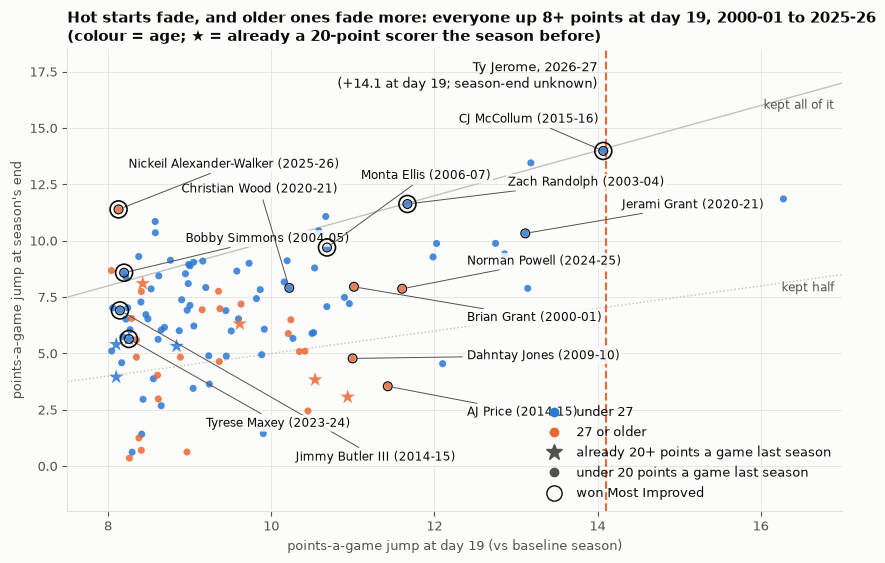

In [7]:
# chart: early jump vs season-end jump for everyone up 8+ points at day 19
x = e[hot].copy()
fig, ax = plt.subplots(figsize=(10, 6))
from matplotlib.lines import Line2D
older = x["age"] >= 27
scorer = x["base_ppg"] >= 20                    # already a 20-point scorer in his baseline season
for is_old, col in [(False, BLUE), (True, ORANGE)]:
    for is_scorer, marker, size in [(False, "o", 26), (True, "*", 120)]:
        m = (older == is_old) & (scorer == is_scorer)
        ax.scatter(x.loc[m, "early_jump"], x.loc[m, "final_jump"], s=size, marker=marker, color=col, alpha=0.85, edgecolor="none", zorder=3)
w = x[x["mip"]]
ax.scatter(w["early_jump"], w["final_jump"], s=150, facecolor="none", edgecolor=INK, linewidth=1.2, zorder=4)
handles = [Line2D([], [], marker="o", linestyle="", color=BLUE, label="under 27"), Line2D([], [], marker="o", linestyle="", color=ORANGE, label="27 or older"),
           Line2D([], [], marker="*", linestyle="", color=INK2, markersize=12, label="already 20+ points a game last season"),
           Line2D([], [], marker="o", linestyle="", color=INK2, label="under 20 points a game last season"),
           Line2D([], [], marker="o", linestyle="", markerfacecolor="none", markeredgecolor=INK, markersize=11, label="won Most Improved")]
lim = (7.5, 17)
ax.plot(lim, lim, color=MUTED, linewidth=1); ax.text(16.9, 16.3, "kept all of it", color=INK2, fontsize=8.5, ha="right", va="top")
ax.plot(lim, [v / 2 for v in lim], color=MUTED, linewidth=1, linestyle=":"); ax.text(16.9, 8.2, "kept half", color=INK2, fontsize=8.5, ha="right", va="top")
ax.axvline(14.1, color=ORANGE, linewidth=1.5, linestyle="--")
ax.annotate("Ty Jerome, 2026-27\n(+14.1 at day 19; season-end unknown)", (14.1, 18), xytext=(-6, 0), ha="right", textcoords="offset points", fontsize=9, color=INK, va="top")
print(f"already 20+ last season: {int(scorer.sum())} of {len(x)}; won: {int(x.loc[scorer, 'mip'].sum())}")
# labels sit in empty space (data coordinates), each joined to its dot by a thin line; labelled dots are outlined
LABELS = {("Nickeil Alexander-Walker", "2025-26"): (8.25, 13.4), ("CJ McCollum", "2015-16"): (12.3, 15.4),
          ("Jerami Grant", "2020-21"): (14.3, 11.6), ("Norman Powell", "2024-25"): (12.4, 9.1),
          ("Christian Wood", "2020-21"): (8.9, 12.3), ("Brian Grant", "2000-01"): (12.4, 6.6),
          ("Tyrese Maxey", "2023-24"): (9.2, 1.9), ("Dahntay Jones", "2009-10"): (12.4, 4.9), ("AJ Price", "2014-15"): (12.4, 2.4),
          ("Zach Randolph", "2003-04"): (12.9, 12.6), ("Monta Ellis", "2006-07"): (11.1, 12.9),
          ("Bobby Simmons", "2004-05"): (8.95, 10.1), ("Jimmy Butler III", "2014-15"): (10.3, 0.4)}
for _, r in x[[(p, s) in LABELS for p, s in zip(x["player_name"], x["season"])]].iterrows():
    tx, ty = LABELS[(r["player_name"], r["season"])]
    ax.scatter(r["early_jump"], r["final_jump"], s=40, facecolor="none", edgecolor=INK, linewidth=0.9, zorder=5)
    ax.annotate(f"{r['player_name']} ({r['season'][:4]}-{r['season'][5:]})", (r["early_jump"], r["final_jump"]), xytext=(tx, ty),
                textcoords="data", fontsize=8.5, color=INK, va="center",
                arrowprops=dict(arrowstyle="-", color=INK2, linewidth=0.7, shrinkA=2, shrinkB=4),
                bbox=dict(boxstyle="round,pad=0.15", facecolor="#fcfcfb", edgecolor="none", alpha=0.85))
ax.set_xlim(*lim); ax.set_ylim(-2, 18.5)
ax.set_xlabel("points-a-game jump at day 19 (vs baseline season)"); ax.set_ylabel("points-a-game jump at season's end")
ax.legend(handles=handles, frameon=False, loc="lower right", fontsize=9)
ax.set_title("Hot starts fade, and older ones fade more: everyone up 8+ points at day 19, 2000-01 to 2025-26\n(colour = age; ★ = already a 20-point scorer the season before)", loc="left", fontsize=11)
fig.savefig(FIG_DIR / "18_ty_jerome_effect.png", dpi=150, bbox_inches="tight")

## 18 findings

**1. There has never been a Ty Jerome.** His +14.1 points at day 19 is the biggest early jump by any player aged 27 or older in 26 seasons. The next biggest were Norman Powell (+11.6, 2024-25) and AJ Price (+11.4, 2014-15).

**2. The strict lookalikes did not win.** Fourteen players were 27+, came off a bench role, and were up 8+ points at this point.
- **They kept about two-thirds of the jump** (median 65%), and only 64% played 70% of their team's games.
- **Three got any votes** (Travis Best 7th, Channing Frye 14th, Kyle Anderson 16th). **None finished in the top 3, and none won.**
- **Our model never gave any of them more than 9%** at this point. Jerome is at about 26%.

**3. Older hot starts fade more than younger ones.**

| Up 8+ points at day 19 | Players | Jump kept (median) | Won |
|---|---|---|---|
| Under 27, bench role last season | 53 | 79% | 3 |
| 27 or older, any role | 31 | 58% | **1** (Nickeil Alexander-Walker, last season) |

So it can happen, and it happened last season. Alexander-Walker was 27, up 8.2 at this point, and kept even more (+11.4 by season's end). He just missed the strict definition above, with 25.3 minutes in his baseline season.

**4. Older early leaders have a poor record.**
- **Three day-19 #1s were 27 or older:** Jarrett Jack (2011-12), Norman Powell (2024-25) and Austin Reaves (2025-26, at 37%). None won; the best finish was Jack's 28th.
- **Across all day-19 top 3s:** 7 players aged 27+ won 0 awards, while 71 under-27s won 9.
- **For context:** all day-19 #1s averaged a 19% chance, and 4 of 26 won.

**5. His 12 closest comparisons didn't win either.** The one top-3 finish was Jerami Grant (2nd, 2020-21). Norman Powell was #1 at this exact point in 2024-25 and got no votes at all.

**6. Already a 20-point scorer (the ★ markers).** Only 8 of the 112 hot starters had scored 20+ points a game the season before, and 1 won (Tyrese Maxey, at 20.3). Jerome isn't one of them, but it's another sign that voters favour players coming from a smaller role.

**7. What's specific to Jerome:**
- **His baseline is stale.** It's 2024-25 (12.5 points). In the 15 games he played last season he averaged 19.7, so part of the jump already happened in a season our baseline rule skips as injury-shortened.
- **Availability.** He played 2 games in 2023-24 and 15 in 2025-26, and he has missed 2 of Memphis's first 10.
- **One big night lifts the average.** Without his 45-point opener he is at 24.0 points, not 26.6.

**What it means.**
- **Jerome is a real candidate but an unlikely winner.** If he keeps the typical 58% of his jump, he finishes around 20.7 points a game: still a big leap (+8), but the kind voters have rewarded only once for a player his age.
- **Our 26% looks too high.** History suggests something nearer the single digits, though notebook 12's model will only reflect that once it's taught to.

**Next (TODO item 2): test these as model inputs, on this branch.**
- **A. An age × early-jump interaction.**
- **B. Recent form instead of a stale baseline:** count an injury-shortened last season if he played enough of it.
- **C. Availability:** games missed so far.

Each is kept only if it improves the strict tests.

## 18C — Testing the ideas as model inputs (TODO item 2)

Three ideas from 18A–18B, each added to the current model (with the scoring turning point at 20 and the All-Star input), and tested at five points of the season, 2000-01 → 2025-26:

| Option | Input | The idea |
|---|---|---|
| **A** | `older_jump`: the early points jump, counted only for players aged 27+ | Older hot starts count for less |
| A2 | `age_x_jump`: (age − 26) × points jump, floored at 0 | The same, on a smooth age scale |
| **B** | `stale`: the baseline season is older than last season (last season was lost or injury-shortened), and `head_start`: how much of the jump already showed in that short season (10+ games) | Jerome's 19.7 points in 15 games last season |
| **C** | `games_share`: games played ÷ the team's games so far | Availability |

**Judged by:** "× a blind guess" (higher is better), how often the winner is in the top 7, in the leave-one-season-out and strict tests. An input is kept only if it helps consistently, not on one day.

In [8]:
from unicorn.hot_start import add_hot_start_inputs

BASE = MH.IN_SEASON_FEATURES + ["over_turn", "prior_allstar"]
VARIANTS = {"current model": BASE, "A: older jump": BASE + ["older_jump"], "A2: age × jump": BASE + ["age_x_jump"],
            "B: stale + head start": BASE + ["stale", "head_start"], "B1: stale only": BASE + ["stale"], "B2: head start only": BASE + ["head_start"],
            "C: games share": BASE + ["games_share"], "A + B + C": BASE + ["older_jump", "stale", "head_start", "games_share"]}
DAYS = [14, 19, 30, 60, 85]

def score(f, feats, scheme):
    lp, r = [], []
    for i, s in enumerate(sorted(f["season"].unique())):
        if scheme == "strict" and i < 5:
            continue
        tr = f[f["season"] < s] if scheme == "strict" else f[f["season"] != s]
        te = f[f["season"] == s]
        if not te["mip"].any():
            continue
        p = ChoiceModel(feats, MH.L2).fit(tr).predict_proba(te)
        lp.append(np.log(p[te["mip"]].iloc[0] * len(te))); r.append(p.rank(ascending=False, method="min")[te["mip"]].iloc[0])
    return np.exp(np.mean(lp)), int((np.array(r) <= 7).sum())

frames, rows = {}, []
sel = load_selections()
for day in DAYS:
    frames[day] = MH.with_turn(add_hot_start_inputs(add_prior_allstar(MH.in_season_frame(g, info, winners, day=day), sel), g, day=day), "base_ppg", 20)
    for name, feats in VARIANTS.items():
        for scheme in ["leave-one-out", "strict"]:
            x, t7 = score(frames[day], feats, "loso" if scheme == "leave-one-out" else "strict")
            rows.append({"day": day, "variant": name, "test": scheme, "× blind guess": x, "winner in top 7": t7})
T = pd.DataFrame(rows)
fit = T.pivot_table(index="variant", columns=["test", "day"], values="× blind guess").loc[list(VARIANTS)]
shown = fit.round(2)
shown[("all", "tests where fit improves (of 10)")] = (fit.sub(fit.loc["current model"], axis=1) > 0).sum(axis=1)
display(shown)
T.pivot_table(index="variant", columns=["test", "day"], values="winner in top 7").loc[list(VARIANTS)]

test                  leave-one-out                            strict        \
day                              14    19     30     60     85     14    19   
variant                                                                       
current model                  9.30  7.87  11.53  18.72  25.50   8.30  6.35   
A: older jump                  9.13  7.76  10.99  17.88  24.30   8.13  6.27   
A2: age × jump                 9.27  7.93  11.43  18.49  25.28   8.30  6.42   
B: stale + head start          9.68  8.11  11.92  19.13  25.71   8.58  6.52   
B1: stale only                 9.68  8.11  11.92  19.14  25.71   8.58  6.52   
B2: head start only            9.35  7.90  11.58  18.70  25.49   8.33  6.37   
C: games share                 9.19  7.57  11.42  18.69  26.30   8.28  6.16   
A + B + C                      9.42  7.70  11.25  18.26  25.21   8.41  6.25   

test                                                                   all  
day                      30     60     85 tests where fit improves (of 10)  
variant                                                                     
current model          9.01  14.22  19.77                                0  
A: older jump          8.53  13.40  18.66                                0  
A2: age × jump         8.96  14.07  19.62                                3  
B: stale + head start  9.25  14.50  19.94                               10  
B1: stale only         9.25  14.51  19.94                               10  
B2: head start only    9.03  14.21  19.76                                6  
C: games share         8.98  14.10  20.46                                2  
A + B + C              8.73  13.56  19.43                                2

test                  leave-one-out                         strict        \
day                              14    19    30    60    85     14    19   
variant                                                                    
current model                  13.0  11.0  17.0  20.0  20.0   10.0  11.0   
A: older jump                  13.0  12.0  17.0  18.0  20.0   10.0  11.0   
A2: age × jump                 13.0  12.0  17.0  20.0  21.0   10.0  11.0   
B: stale + head start          13.0  12.0  17.0  19.0  20.0   10.0  11.0   
B1: stale only                 13.0  12.0  17.0  19.0  20.0   10.0  11.0   
B2: head start only            13.0  11.0  17.0  20.0  20.0   10.0  11.0   
C: games share                 13.0  11.0  16.0  20.0  20.0   10.0  11.0   
A + B + C                      13.0  14.0  17.0  18.0  20.0   10.0  11.0   

test                                     
day                      30    60    85  
variant                                  
current model          11.0  16.0  17.0  
A: older jump          11.0  15.0  17.0  
A2: age × jump         12.0  16.0  17.0  
B: stale + head start  11.0  16.0  17.0  
B1: stale only         11.0  16.0  17.0  
B2: head start only    11.0  16.0  17.0  
C: games share         12.0  16.0  16.0  
A + B + C              12.0  15.0  16.0

In [9]:
# how rare is a stale baseline, and did any such player ever win?
f19 = frames[19]
full = add_hot_start_inputs(MH.in_season_frame(g, info, winners), g)
m = ChoiceModel(BASE + ["stale"], MH.L2).fit(f19)
odds = np.exp(m.coefficients()["stale"] / m.std_[-1])
print(f"stale baseline: {f19['stale'].mean():.1%} of day-19 candidates; winners with one, 2000-01 → 2025-26: {int(full.loc[full['mip'], 'stale'].sum())} of 26 "
      f"(about {full['stale'].mean() * 26:.1f} expected if it made no difference; chance of 0 then ≈ {np.exp(-full['stale'].mean() * 26):.0%})")
print(f"weight at day 19: odds × {odds:.2f} for a player whose last season was lost or injury-shortened")

stale baseline: 4.7% of day-19 candidates; winners with one, 2000-01 → 2025-26: 0 of 26 (about 1.2 expected if it made no difference; chance of 0 then ≈ 30%)
weight at day 19: odds × 0.20 for a player whose last season was lost or injury-shortened


In [10]:
# what it would do to the 2026-27 race today (same build as notebook 12)
from unicorn.labels import MIP_WINNERS
from unicorn.gamelogs import mip_candidates
from unicorn.mip import AGE, GAMELOG_DEFENSE, GAMELOG_DELTAS, RELATIVE, SECOND_YEAR, TEAM
from unicorn.raw import PROJECT_ROOT
ps = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_season.parquet")
latest = ps[ps["season_start"] < 2026].sort_values("season_start").groupby("player_id").tail(1)
ps_live = pd.concat([ps, latest[["player_id"]].assign(season_start=2026, age=latest["age"] + (2026 - latest["season_start"]),
                                                      exp=latest["exp"] + (2026 - latest["season_start"]))], ignore_index=True)
D = int(live.loc[live["season"] == "2026-27", "day"].max())
c = mip_candidates(live[live["day"] <= D], ps_live, min_prior_seasons=1, season_stats=False)
c["second_year"] = (c["prior_seasons"] == 1).astype(float)
c["mip"] = [MIP_WINNERS.get(s) == p for s, p in zip(c["season"], c["player_id"])]
c = MH.with_turn(add_hot_start_inputs(add_prior_allstar(c[c["eligible"] & (c["season_start"] >= 2011)], sel), live, day=D), "base_ppg", 20)
EARLY = GAMELOG_DELTAS + GAMELOG_DEFENSE + RELATIVE + TEAM + AGE + SECOND_YEAR + ["base_ppg", "prior_allstar", "over_turn"]
h, t = c[c["season"] != "2026-27"], c[c["season"] == "2026-27"]
boards = {}
for label, feats in [("live race now", EARLY), ("with 'stale baseline'", EARLY + ["stale"])]:
    p = ChoiceModel(feats, MH.L2).fit(h).predict_proba(t)
    top = t.assign(chance=p).nlargest(7, "chance")
    boards[label] = [f"{n} ({x:.1%})" for n, x in zip(top["player_name"], top["chance"])]
pd.DataFrame(boards, index=pd.RangeIndex(1, 8, name="rank"))

,live race now,with 'stale baseline'
rank,,
1,Ty Jerome (26.5%),Ty Jerome (8.3%)
2,Kyshawn George (3.4%),Kyshawn George (4.5%)
3,Ajay Mitchell (3.0%),Ajay Mitchell (4.0%)
4,Terrence Shannon Jr (2.3%),Terrence Shannon Jr (3.1%)
5,Anthony Black (2.2%),Anthony Black (3.0%)
6,Davion Mitchell (2.0%),Davion Mitchell (2.7%)
7,Ayo Dosunmu (1.9%),Ayo Dosunmu (2.5%)


### 18C findings

| Option | Fit improves in (of 10 tests) | Verdict |
|---|---|---|
| A: older jump | none | ❌ The model's existing age penalty already covers it |
| A2: age × jump | a few, by tiny amounts | ❌ |
| **B1: stale baseline** | **all 10** | ✅ The only consistent gain |
| B2: head start | about half, by tiny amounts | ❌ Adds nothing beyond B1 |
| C: games share | mixed | ❌ |
| A + B + C | fewer than B1 alone | ❌ |

**What the stale-baseline input says:**
- **About 1 candidate in 20 is coming back from a lost or injury-shortened season.** None of the 26 winners since 2000-01 was.
- **The model gives them about a fifth of the odds.** Voters appear to treat a comeback as a *return*, not an *improvement*.
- **For Jerome today:** his chance falls from 26.5% to about 8%, in line with notebook 18's history. He stays #1.

**Caveats:**
- **The evidence is thinner than for the All-Star input** (D38). Zero winners against about 1.2 expected would happen about 3 times in 10 by chance.
- **The case for it is the consistency:** better fit at every point of the season, in both tests.
- **None of the options fixes the overconfidence of early leaders.** That is item 3, calibration.

**Recommendation:** adopt `stale` in the live race (notebook 12), test it in the preseason model (notebook 11) before adding it there, and log it as D39. Drop A, A2, B2 and C.